# A3 · Exploring the messy export (EDA)

**You are the detective.** `data/raw_emr_export.csv` is what the hospital handed over. **Eight kinds of data problem** are hidden in it. Find as many as you can.

**Rules**
1. **Look, don't change.** Nothing in this notebook modifies the data; fixing happens in A4. EDA that "fixes as it goes" destroys the evidence.
2. **Write every finding in the problem log** (next cell) with *numbers*: how many rows, what proportion, an example.
3. **Don't open** `slotpred/_messy_export.py` (spoiler) or `data/_hidden_truth.csv` (that's for the oracle only, never for a model).

Each check has a short **why**, given code where it's plumbing, and `TODO(you)` where the looking is yours.

## Problem log (fill this in as you go)

| # | Problem | Evidence (numbers, example) | Rows affected | Likely cause | Fix to try in A4 |
|---|---|---|---|---|---|
| 1 | Exact duplicate rows | 177 rows are exact copies; 177 repeated `appointment_id`s, all identical (e.g. A000270, A043941) | 177 (0.4%) | Export/ETL ran twice or re-sent records | Drop duplicates on `appointment_id` (keep first) |
| 2 | Inconsistent category labels | `doctor` has 105 distinct values vs 21 real (e.g. "Dr. Nikhil Verma", " dr nikhil verma", "DR NIKHIL VERMA", "Nikhil V."); `visit_type` has 9 vs 2 (`New`, `NEW`, `new visit`, `follow up`, `followup`...) | ~1.3k visit_type rows plus many doctor variants | Free-text entry, no controlled vocabulary | Strip, lower-case, remove "Dr.", map initials/variants to the canonical 21 doctors / 2 visit types |
| 3 | Placeholder age 999 | `age.max()` = 999; 42 rows have age 999 (age 0 appears in 428 rows, check if real) | 42 (0.09%) | 999 used as an "unknown" code | Replace 999 with NaN, then impute (median by department / visit type) |
| 4 | Missing age | 864 NaN (1.94%); rate flat across clinics (1.63-2.08%); also why `age` is float | 864 | MCAR-like random omission | Impute median (+ missing flag); dropping is safe |
| 5 | Missing consult_end (target is NaN) | 120 NaN (0.27%), spread across all clinics and months (0.15-0.38%/month) | 120 | MCAR-like: visit never closed in the EMR | Drop from training (no target) |
| 6 | Impossible durations | 214 consults under 1 min (min 0.02 min = 1 s) and 476 over 120 min (up to ~320 min), spread over all clinics/months | 690 (1.6%) | Data entry / clock errors | Apply domain rule (1 <= minutes <= 120), drop or cap; use log-scale IQR (777 flags vs 2,465 raw) |
| 7 | Whitefield process change (Mar-Apr 2026) | `consult_start == check_in` in 1,712 rows, all Whitefield, Mar (921) + Apr (791); Whitefield monthly median 26.1-26.9 min vs ~12 min other months | 1,712 | Software/process change copied `check_in` into `consult_start`, so target includes waiting time | Exclude or re-derive those rows, or add a period flag |
| 8 | Timestamp order broken | `consult_end <= consult_start` (0 min) in 0 rows in this export; `consult_start < check_in` in 0 rows | 0 | Clock / entry error | Drop (non-positive duration) |

In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from slotpred.eda import load_raw, log_hist, monthly_median

raw = load_raw()
print(raw.shape)

(44514, 15)


## Check 1 - Shape and types

**Why:** a column with the wrong type hides problems. Dates stored as text can't be compared; a number stored as float may be hiding missing values (NaN forces int to float).

In [2]:
display(raw.head())
raw.dtypes

,appointment_id,date,slot_time,clinic,doctor,department,patient_id,patient_name,age,visit_type,prior_reports,teleconsult,check_in,consult_start,consult_end
0,A002202,2026-01-13,10:15,HSR,Anita Sharma,Cardiology,P03272,Rohan,36.0,new,2,False,2026-01-13 10:06:14,2026-01-13 10:17:53,2026-01-13 10:38:33
1,A016039,2026-03-31,13:45,HSR,Priya Nair,Paediatrics,P03352,Manoj,2.0,new,3,False,2026-03-31 13:38:37,2026-03-31 13:48:33,2026-03-31 14:14:50
2,A021373,2026-04-30,10:45,Jayanagar,Neha Gupta,General Medicine,P04259,Riya,63.0,new,0,False,2026-04-30 10:41:13,2026-04-30 10:47:43,2026-04-30 11:13:56
3,A012750,2026-03-12,16:15,Whitefield,Vikram Shetty,ENT,P01974,Kiran,38.0,new,1,False,2026-03-12 16:08:27,2026-03-12 16:08:27,2026-03-12 16:25:20
4,A040714,2026-08-12,13:00,Jayanagar,Asha Hegde,Dermatology,P01555,Srinivas,49.0,follow-up,1,False,2026-08-12 12:58:37,2026-08-12 13:00:21,2026-08-12 13:09:00


appointment_id        str
date                  str
slot_time             str
clinic                str
doctor                str
department            str
patient_id            str
patient_name          str
age               float64
visit_type            str
prior_reports       int64
teleconsult          bool
check_in              str
consult_start         str
consult_end           str
dtype: object

**Questions:** Which columns are text but should be dates or times? Why might `age` be a float when ages are whole numbers?

*Answer:* consult_start and consult_end and check_in  should be tiem and and date should be date but now all are in string,beacuse age is missing values in few rows and automatic fill is there 

In [3]:
# Date column
raw["date"] = pd.to_datetime(raw["date"])

# Full timestamps (these are likely "HH:MM" strings or full datetimes)
for col in ["check_in", "consult_start", "consult_end"]:
    raw[col] = pd.to_datetime(raw[col], errors="coerce")

#raw["slot_time"] = pd.to_datetime(raw["slot_time"], errors="coerce").dt.time
#Better: combine with the date for a full datetime64 (best for modelling and EDA)
raw["slot_dt"] = pd.to_datetime(
    raw["date"].dt.strftime("%Y-%m-%d") + " " + raw["slot_time"].astype(str),
    errors="coerce",
)

In [4]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 44514 entries, 0 to 44513
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   appointment_id  44514 non-null  str           
 1   date            44514 non-null  datetime64[us]
 2   slot_time       44514 non-null  str           
 3   clinic          44514 non-null  str           
 4   doctor          44514 non-null  str           
 5   department      44514 non-null  str           
 6   patient_id      44514 non-null  str           
 7   patient_name    44514 non-null  str           
 8   age             43650 non-null  float64       
 9   visit_type      44514 non-null  str           
 10  prior_reports   44514 non-null  int64         
 11  teleconsult     44514 non-null  bool          
 12  check_in        44514 non-null  datetime64[us]
 13  consult_start   44514 non-null  datetime64[us]
 14  consult_end     44394 non-null  datetime64[us]
 15  slot_dt      

## Check 2 - Keys and duplicates

**Why:** `appointment_id` should identify exactly one visit. Duplicates count a visit twice: double weight in training, and if one copy lands in train and the other in test, the model is tested on a visit it has already seen (a form of leakage).

In [5]:
# TODO(you):
# 1. How many rows are EXACT duplicates of another row?           hint: raw.duplicated()

display(raw.duplicated().sum())

# 2. How many appointment_ids appear more than once?              hint: raw["appointment_id"].duplicated()
display(raw["appointment_id"].duplicated().sum())

# 3. Are the repeated ids always exact copies, or do some differ?  compare 1 and 2
display(raw[raw["appointment_id"].duplicated(keep=False)].sort_values("appointment_id"))
# they are exactly the same

np.int64(177)

np.int64(177)

,appointment_id,date,slot_time,clinic,doctor,department,patient_id,patient_name,age,visit_type,prior_reports,teleconsult,check_in,consult_start,consult_end,slot_dt
35365,A000270,2026-01-02,16:00,HSR,Kavita Iyer,Gynaecology,P03744,Priya,44.0,new,0,False,2026-01-02 15:41:42,2026-01-02 16:00:56,2026-01-02 16:16:07,2026-01-02 16:00:00
39357,A000270,2026-01-02,16:00,HSR,Kavita Iyer,Gynaecology,P03744,Priya,44.0,new,0,False,2026-01-02 15:41:42,2026-01-02 16:00:56,2026-01-02 16:16:07,2026-01-02 16:00:00
15030,A000656,2026-01-05,15:45,HSR,Deepak Rao,General Medicine,P05239,Aryan,52.0,new,0,False,2026-01-05 15:27:21,2026-01-05 15:51:08,2026-01-05 15:59:12,2026-01-05 15:45:00
18029,A000656,2026-01-05,15:45,HSR,Deepak Rao,General Medicine,P05239,Aryan,52.0,new,0,False,2026-01-05 15:27:21,2026-01-05 15:51:08,2026-01-05 15:59:12,2026-01-05 15:45:00
4488,A000887,2026-01-06,12:00,Indiranagar,Divya Rao,Dermatology,P04146,Vivaan,55.0,new,1,False,2026-01-06 11:56:35,2026-01-06 12:02:50,2026-01-06 12:09:19,2026-01-06 12:00:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14106,A043633,2026-08-28,15:30,Jayanagar,Anita Sharma,Cardiology,P05568,Bhavna,58.0,new,1,False,2026-08-28 15:20:25,2026-08-28 15:36:05,2026-08-28 16:06:22,2026-08-28 15:30:00
9931,A043639,2026-08-28,11:00,Whitefield,Rahul Menon,Cardiology,P04436,Mary,80.0,follow-up,0,False,2026-08-28 10:44:00,2026-08-28 11:32:21,2026-08-28 11:40:05,2026-08-28 11:00:00
28056,A043639,2026-08-28,11:00,Whitefield,Rahul Menon,Cardiology,P04436,Mary,80.0,follow-up,0,False,2026-08-28 10:44:00,2026-08-28 11:32:21,2026-08-28 11:40:05,2026-08-28 11:00:00
20882,A043941,2026-08-29,13:45,Koramangala,Suresh Kumar,Orthopaedics,P05269,Vijay,32.0,new,0,False,2026-08-29 13:33:59,2026-08-29 13:45:27,2026-08-29 13:58:32,2026-08-29 13:45:00


## Check 3 - Missing values

**Why:** *how many* is missing matters, but *which rows* matters more:

| Type | Meaning | Example | Danger |
|---|---|---|---|
| **MCAR** (missing completely at random) | Missingness unrelated to anything | A random export glitch | Low: dropping rows is fine |
| **MAR** (missing at random, given other columns) | Depends on something you can see | One clinic never records age | Medium: fill using that column |
| **MNAR** (missing not at random) | Depends on the missing value itself | End time missing because the visit was so long the doctor forgot | High: dropping biases the data |

In [6]:
# TODO(you):
# 1. Missing count AND percentage per column.                      hint: raw.isna().sum(), raw.isna().mean()
display(raw.isna().sum())
display(raw.isna().mean())
# 2. For each column with missing values: is the missing rate the same in every clinic? every month?
# display(raw.assign(missing=raw["age"].isna()).groupby("clinic")["missing"].sum())
# display(raw.assign(missing=raw["age"].isna()).groupby("clinic")["missing"].mean())

# display(
#     raw.groupby(raw["date"].dt.to_period("M"))["consult_end"]
#        .apply(lambda s: s.isna().mean())
# )


def missing_rate(df, col, by):
    #return df[col].isna().groupby(by).mean()
    # if has to compute mean and sum at a time 
    return df[col].isna().groupby(by).agg(["mean", "sum"])

display(missing_rate(raw, "age", raw["clinic"]))
display(missing_rate(raw, "consult_end", raw["date"].dt.to_period("M")))


#    hint: raw.assign(missing=raw["COL"].isna()).groupby("clinic")["missing"].mean()

appointment_id      0
date                0
slot_time           0
clinic              0
doctor              0
department          0
patient_id          0
patient_name        0
age               864
visit_type          0
prior_reports       0
teleconsult         0
check_in            0
consult_start       0
consult_end       120
slot_dt             0
dtype: int64

appointment_id    0.000000
date              0.000000
slot_time         0.000000
clinic            0.000000
doctor            0.000000
department        0.000000
patient_id        0.000000
patient_name      0.000000
age               0.019410
visit_type        0.000000
prior_reports     0.000000
teleconsult       0.000000
check_in          0.000000
consult_start     0.000000
consult_end       0.002696
slot_dt           0.000000
dtype: float64

,mean,sum
clinic,,
HSR,0.020846,231
Indiranagar,0.019918,174
Jayanagar,0.019985,184
Koramangala,0.019309,142
Whitefield,0.016347,133


,mean,sum
date,,
2026-01,0.002723,16
2026-02,0.003586,18
2026-03,0.001667,9
2026-04,0.003410,18
2026-05,0.001464,8
2026-06,0.003780,21
2026-07,0.002755,17
2026-08,0.002262,13


## Check 4 - Categories

**Why:** "Dr. Deepak Rao", "DR DEEPAK RAO" and "Deepak R." are one doctor to a human and three doctors to a model, each with a third of the data.

**Reference from the hospital:** 21 doctors, 8 departments, 5 clinics, 2 visit types (`new`, `follow-up`). Every doctor belongs to exactly one department.

In [7]:
# TODO(you):
# 1. Number of distinct values in doctor, department, clinic, visit_type. Compare with the reference.   hint: .nunique()
display(raw["doctor"].nunique())
display(raw["department"].nunique())
display(raw["clinic"].nunique())
display(raw["visit_type"].nunique())
# 2. Look at the actual values of any column that has too many.   hint: .value_counts()

display(raw["doctor"].value_counts())
display(raw["department"].value_counts())
display(raw["clinic"].value_counts())
display(raw["visit_type"].value_counts())

# 3. Does every doctor appear in exactly one department?    hint: raw.groupby("doctor")["department"].nunique()
display(raw.groupby("doctor")["department"].nunique())

# 4. Does every department appear in exactly one clinic?    hint: raw.groupby("department")["clinic"].nunique()
display(raw.groupby("department")["clinic"].nunique())

105

8

5

9

doctor
Lakshmi Krishnan     2281
Meera Pillai         2251
Rohan Desai          2198
Arjun Reddy          2186
Anita Sharma         2176
                     ... 
Dr. Pooja Bhat         11
Dr. Nikhil Verma       10
 dr nikhil verma        6
DR NIKHIL VERMA         5
Nikhil V.               4
Name: count, Length: 105, dtype: int64

department
Paediatrics         7143
Cardiology          6608
Orthopaedics        6583
General Medicine    6395
Gynaecology         4594
Neurology           4583
ENT                 4406
Dermatology         4202
Name: count, dtype: int64

clinic
HSR            11081
Jayanagar       9207
Indiranagar     8736
Whitefield      8136
Koramangala     7354
Name: count, dtype: int64

visit_type
follow-up    24314
new          18877
New            217
followup       203
follow up      187
Follow-up      184
FOLLOW-UP      178
new visit      178
NEW            176
Name: count, dtype: int64

doctor
 dr anita sharma     1
 dr arjun reddy      1
 dr asha hegde       1
 dr deepak rao       1
 dr divya rao        1
                    ..
Sanjay Patil         1
Suresh K.            1
Suresh Kumar         1
Vikram S.            1
Vikram Shetty        1
Name: department, Length: 105, dtype: int64

department
Cardiology          5
Dermatology         4
ENT                 4
General Medicine    5
Gynaecology         4
Neurology           4
Orthopaedics        5
Paediatrics         5
Name: clinic, dtype: int64

## Check 5 - Numbers: impossible and placeholder values

**Why:** systems often store "unknown" as a fake number (999, -1, 0). A model treats 999 as a real, very old patient.

In [8]:
# TODO(you):
# 1. raw.describe() for the numeric columns. Anything impossible?
display(raw.describe())
# 2. Look at the most common values and the extremes of age.      hint: .value_counts().head(), .sort_values()
display(raw["age"].value_counts().head())
display(raw["age"].sort_values())
display(raw["age"].sort_values(ascending=False))
# 3. Is prior_reports sensible for every visit type?               hint: groupby visit_type, describe
display(raw.groupby("visit_type")["prior_reports"].describe())

,date,age,prior_reports,check_in,consult_start,consult_end,slot_dt
count,44514,43650.000000,44514.000000,44514,44514,44394,44514
mean,2026-05-03 03:25:19.288313,40.648958,1.030552,2026-05-03 16:37:50.915712,2026-05-03 16:51:15.615829,2026-05-03 17:18:37.403973,2026-05-03 16:47:48.964820
min,2026-01-01 00:00:00,0.000000,0.000000,2026-01-01 08:49:55,2026-01-01 09:03:21,2026-01-01 09:11:24,2026-01-01 09:00:00
25%,2026-03-03 00:00:00,25.000000,0.000000,2026-03-03 10:29:44,2026-03-03 10:37:32.750000,2026-03-03 11:04:24.500000,2026-03-03 10:33:45
50%,2026-05-05 00:00:00,42.000000,1.000000,2026-05-05 10:44:18,2026-05-05 11:00:06.500000,2026-05-05 11:17:20.500000,2026-05-05 11:00:00
75%,2026-07-04 00:00:00,55.000000,2.000000,2026-07-04 12:44:11.500000,2026-07-04 12:50:06.250000,2026-07-04 13:14:01.500000,2026-07-04 12:45:00
max,2026-08-31 00:00:00,999.000000,10.000000,2026-08-31 17:41:27,2026-08-31 17:49:41,2026-08-31 18:12:18,2026-08-31 17:45:00
std,NaN,36.124786,1.206700,NaN,NaN,NaN,NaN


age
16.0    1572
46.0     982
43.0     964
42.0     954
45.0     938
Name: count, dtype: int64

11276    0.0
28841    0.0
28875    0.0
35047    0.0
3524     0.0
        ... 
44322    NaN
44366    NaN
44371    NaN
44376    NaN
44455    NaN
Name: age, Length: 44514, dtype: float64

15811    999.0
14306    999.0
43334    999.0
20530    999.0
41192    999.0
         ...  
44322      NaN
44366      NaN
44371      NaN
44376      NaN
44455      NaN
Name: age, Length: 44514, dtype: float64

,count,mean,std,min,25%,50%,75%,max
visit_type,,,,,,,,
FOLLOW-UP,178.0,0.539326,0.744944,0.0,0.0,0.0,1.0,4.0
Follow-up,184.0,0.586957,0.811828,0.0,0.0,0.0,1.0,4.0
NEW,176.0,1.630682,1.494742,0.0,0.0,1.0,3.0,8.0
New,217.0,1.474654,1.308998,0.0,0.0,1.0,2.0,7.0
follow up,187.0,0.631016,0.781301,0.0,0.0,0.0,1.0,4.0
follow-up,24314.0,0.603274,0.771548,0.0,0.0,0.0,1.0,6.0
followup,203.0,0.527094,0.719602,0.0,0.0,0.0,1.0,4.0
new,18877.0,1.583302,1.424743,0.0,1.0,1.0,2.0,10.0
new visit,178.0,1.584270,1.304568,0.0,1.0,1.0,2.0,6.0


## Check 6 - The target: consult minutes

**Why:** the EMR has no "duration" column. You derive the target from two timestamps, and every problem in those timestamps becomes a problem in the target.

### Outliers: two ways to define "suspicious"

**Statistical (IQR rule):** $\text{IQR} = Q_3 - Q_1$; flag values below $Q_1 - 1.5\,\text{IQR}$ or above $Q_3 + 1.5\,\text{IQR}$.
Consult times are right-skewed, so on the raw scale the rule flags many *genuine* long visits. Apply it to **log(minutes)** instead, where the skew is gone.

**Domain rule:** "a consult cannot take under 1 minute or over 2 hours". Statistics tell you *what's unusual*; only domain knowledge tells you *what's impossible*. Unusual is not the same as wrong.

In [9]:
# TODO(you): build the target, without changing `raw`
# 1. Parse consult_start and consult_end with pd.to_datetime. -> already done previous cell
# 2. minutes = (end - start) in minutes.          hint: .dt.total_seconds() / 60
minutes = (raw["consult_end"] - raw["consult_start"]).dt.total_seconds() / 60
# 3. How many are NaN? negative? under 1 minute? over 120 minutes?
display(minutes.isna().sum())
display((minutes < 0).sum())
display((minutes < 1).sum())
display((minutes > 120).sum())
# minutes = None   # replace

np.int64(120)

np.int64(0)

np.int64(214)

np.int64(476)

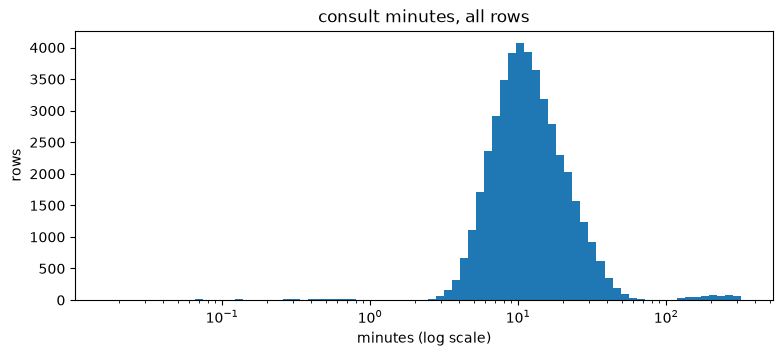

In [10]:
# Given: the shape of the target on a log scale (run after your cell above)
log_hist(minutes, title="consult minutes, all rows")
plt.show()

In [11]:
# TODO(you):
# 1. IQR fences on minutes, then on np.log(minutes). How many rows does each flag? Which do you trust more, and why?
Q1 = minutes.quantile(0.25)
Q3 = minutes.quantile(0.75)
IQR = Q3 - Q1
fence_low = Q1 - 1.5 * IQR
fence_high = Q3 + 1.5 * IQR
flag_minutes = (minutes < fence_low) | (minutes > fence_high)
flag_minutes = (minutes < fence_low) | (minutes > fence_high)
print("Number of Flags by Minutes:", flag_minutes.sum())

# log only defined for positive values; others become NaN (and are not flagged)
log_minutes = np.log(minutes.where(minutes > 0))           
Q1_log = log_minutes.quantile(0.25) # type: ignore
Q3_log = log_minutes.quantile(0.75) # type: ignore
IQR_log = Q3_log - Q1_log
fence_low_log = Q1_log - 1.5 * IQR_log
fence_high_log = Q3_log + 1.5 * IQR_log
flag_log_minutes = (log_minutes < fence_low_log) | (log_minutes > fence_high_log)
print("Number of Flags by Log Minutes:", flag_log_minutes.sum())

# Display the rows flagged by each method for comparison
print("Flagged by Minutes")
display(raw[flag_minutes])
print("Flagged by Log Minutes")
display(raw[flag_log_minutes])

# 3. Compare the flagged rows with the original minutes column
print("Minutes Flagged by Minutes")
display(minutes[flag_minutes])
print("Minutes Flagged by Log Minutes")
display(minutes[flag_log_minutes])

# 2. Print the 10 shortest and 10 longest consults with all their columns. What do they have in common?
shortest_idx = minutes.nsmallest(10).index
longest_idx = minutes.nlargest(10).index
print("Shortest Consults")
display(raw.loc[shortest_idx])
print("Longest Consults")
display(raw.loc[longest_idx])

# 4. Compare the flagged rows with the shortest and longest consults
flagged_minutes_idx = flag_minutes.index[flag_minutes.to_numpy()]
print("Shortest Consults Flagged by Minutes")
display(raw.loc[shortest_idx.intersection(flagged_minutes_idx)])
print("Longest Consults Flagged by Minutes")
display(raw.loc[longest_idx.intersection(flagged_minutes_idx)])

Number of Flags by Minutes: 2465
Number of Flags by Log Minutes: 777
Flagged by Minutes


,appointment_id,date,slot_time,clinic,doctor,department,patient_id,patient_name,age,visit_type,prior_reports,teleconsult,check_in,consult_start,consult_end,slot_dt
17,A020301,2026-04-23,16:45,Whitefield,Farah Siddiqui,Neurology,P04884,Aadhya,20.0,new,6,False,2026-04-23 16:33:53,2026-04-23 16:33:53,2026-04-23 17:36:45,2026-04-23 16:45:00
30,A019511,2026-04-20,15:45,Whitefield,Rahul Menon,Cardiology,P00734,Meera,60.0,follow-up,0,False,2026-04-20 15:30:04,2026-04-20 15:30:04,2026-04-20 16:06:51,2026-04-20 15:45:00
45,A019703,2026-04-20,11:30,HSR,dr manoj joshi,Orthopaedics,P04920,Arjun,51.0,new,0,False,2026-04-20 11:22:49,2026-04-20 11:31:43,2026-04-20 14:48:04,2026-04-20 11:30:00
75,A017895,2026-04-10,17:45,Jayanagar,Meera Pillai,Neurology,P01224,Anil,32.0,new,2,False,2026-04-10 17:29:49,2026-04-10 18:13:03,2026-04-10 18:50:56,2026-04-10 17:45:00
84,A007932,2026-02-12,13:30,Indiranagar,Karthik Subramanian,Cardiology,P03522,Harish,35.0,new,5,False,2026-02-12 13:24:54,2026-02-12 13:32:45,2026-02-12 14:07:02,2026-02-12 13:30:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44459,A018726,2026-04-15,14:15,Indiranagar,Kavita Iyer,Gynaecology,P00838,Aadhya,67.0,new,2,False,2026-04-15 14:09:53,2026-04-15 14:15:43,2026-04-15 14:52:28,2026-04-15 14:15:00
44472,A032427,2026-06-30,14:15,HSR,Farah Siddiqui,Neurology,P03696,Dev,63.0,follow-up,1,False,2026-06-30 13:57:12,2026-06-30 14:29:26,2026-06-30 17:52:14,2026-06-30 14:15:00
44484,A014677,2026-03-23,14:30,Whitefield,Neha Gupta,General Medicine,P03081,Ananya,39.0,new,2,False,2026-03-23 14:19:04,2026-03-23 14:19:04,2026-03-23 14:51:26,2026-03-23 14:30:00
44496,A018580,2026-04-14,14:15,Koramangala,Meera Pillai,Neurology,P05939,Esha,22.0,new,2,False,2026-04-14 14:09:44,2026-04-14 14:16:29,2026-04-14 14:47:17,2026-04-14 14:15:00


Flagged by Log Minutes


,appointment_id,date,slot_time,clinic,doctor,department,patient_id,patient_name,age,visit_type,prior_reports,teleconsult,check_in,consult_start,consult_end,slot_dt
17,A020301,2026-04-23,16:45,Whitefield,Farah Siddiqui,Neurology,P04884,Aadhya,20.0,new,6,False,2026-04-23 16:33:53,2026-04-23 16:33:53,2026-04-23 17:36:45,2026-04-23 16:45:00
45,A019703,2026-04-20,11:30,HSR,dr manoj joshi,Orthopaedics,P04920,Arjun,51.0,new,0,False,2026-04-20 11:22:49,2026-04-20 11:31:43,2026-04-20 14:48:04,2026-04-20 11:30:00
321,A023222,2026-05-11,15:30,HSR,Kavita Iyer,Gynaecology,P04791,Dev,64.0,follow-up,0,False,2026-05-11 15:16:17,2026-05-11 15:30:56,2026-05-11 18:48:49,2026-05-11 15:30:00
324,A036681,2026-07-22,09:45,Indiranagar,Kavita Iyer,Gynaecology,P03584,Mary,32.0,new,2,False,2026-07-22 09:42:56,2026-07-22 09:52:35,2026-07-22 09:53:01,2026-07-22 09:45:00
431,A005505,2026-01-30,14:45,Indiranagar,Vikram Shetty,ENT,P02225,Ishaan,31.0,follow-up,0,False,2026-01-30 14:43:34,2026-01-30 14:52:31,2026-01-30 19:15:05,2026-01-30 14:45:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44308,A005891,2026-02-02,14:30,HSR,Priya Nair,Paediatrics,P00074,Diya,8.0,follow-up,0,False,2026-02-02 14:21:19,2026-02-02 14:34:05,2026-02-02 17:20:32,2026-02-02 14:30:00
44344,A030345,2026-06-18,14:30,Indiranagar,Pooja Bhat,Paediatrics,P04080,Geeta,4.0,follow-up,0,False,2026-06-18 14:15:45,2026-06-18 14:30:05,2026-06-18 14:30:52,2026-06-18 14:30:00
44428,A039605,2026-08-06,15:30,Indiranagar,Vikram Shetty,ENT,P04517,Ganesh,82.0,new,1,False,2026-08-06 15:25:10,2026-08-06 15:34:51,2026-08-06 19:15:54,2026-08-06 15:30:00
44464,A012479,2026-03-11,12:30,HSR,Anita Sharma,Cardiology,P03830,Mary,69.0,new,1,False,2026-03-11 12:24:41,2026-03-11 12:31:11,2026-03-11 12:31:19,2026-03-11 12:30:00


Minutes Flagged by Minutes


...

,appointment_id,date,slot_time,clinic,doctor,department,patient_id,patient_name,age,visit_type,prior_reports,teleconsult,check_in,consult_start,consult_end,slot_dt
43542,A020473,2026-04-24,14:00,Whitefield,Neha Gupta,General Medicine,P02069,Mary,44.0,follow-up,2,False,2026-04-24 13:46:32,2026-04-24 13:46:32,2026-04-24 19:06:03,2026-04-24 14:00:00
7775,A013338,2026-03-16,14:30,Whitefield,Priya Nair,Paediatrics,P00052,Zoya,15.0,new,0,False,2026-03-16 14:12:22,2026-03-16 14:12:22,2026-03-16 19:26:28,2026-03-16 14:30:00
18468,A012296,2026-03-10,15:30,Whitefield,Priya Nair,Paediatrics,P00536,Manoj,6.0,follow-up,2,False,2026-03-10 15:10:02,2026-03-10 15:10:02,2026-03-10 20:18:01,2026-03-10 15:30:00
21711,A020156,2026-04-22,16:00,HSR,Manoj Joshi,Orthopaedics,P02678,Myra,17.0,follow-up,1,False,2026-04-22 15:50:50,2026-04-22 16:03:45,2026-04-22 21:03:43,2026-04-22 16:00:00
7138,A004186,2026-01-23,16:45,Jayanagar,Neha Gupta,General Medicine,P02248,Shalini,39.0,new,0,False,2026-01-23 16:30:14,2026-01-23 16:47:13,2026-01-23 21:47:02,2026-01-23 16:45:00
19819,A005992,2026-02-02,12:45,HSR,Imran Khan,General Medicine,P00954,Manoj,60.0,follow-up,0,False,2026-02-02 12:29:28,2026-02-02 12:47:08,2026-02-02 17:46:26,2026-02-02 12:45:00
16903,A037584,2026-07-27,14:45,Whitefield,Rahul Menon,Cardiology,P04872,Amit,52.0,new,4,False,2026-07-27 14:33:14,2026-07-27 14:53:55,2026-07-27 19:52:44,2026-07-27 14:45:00
27383,A005655,2026-01-31,17:00,Whitefield,Rahul Menon,Cardiology,P04263,Suresh,53.0,follow-up,0,False,2026-01-31 16:43:38,2026-01-31 17:07:57,2026-01-31 22:05:10,2026-01-31 17:00:00
42635,A035427,2026-07-15,14:45,Indiranagar,Manoj Joshi,Orthopaedics,P01641,Ramesh,29.0,follow-up,1,False,2026-07-15 14:39:57,2026-07-15 14:49:39,2026-07-15 19:46:34,2026-07-15 14:45:00
16231,A010498,2026-02-27,13:15,Whitefield,Lakshmi Krishnan,Gynaecology,P04368,Rohan,57.0,follow-up,0,True,2026-02-27 12:56:45,2026-02-27 13:16:46,2026-02-27 18:13:39,2026-02-27 13:15:00


Shortest Consults Flagged by Minutes


,appointment_id,date,slot_time,clinic,doctor,department,patient_id,patient_name,age,visit_type,prior_reports,teleconsult,check_in,consult_start,consult_end,slot_dt


Longest Consults Flagged by Minutes


,appointment_id,date,slot_time,clinic,doctor,department,patient_id,patient_name,age,visit_type,prior_reports,teleconsult,check_in,consult_start,consult_end,slot_dt
43542,A020473,2026-04-24,14:00,Whitefield,Neha Gupta,General Medicine,P02069,Mary,44.0,follow-up,2,False,2026-04-24 13:46:32,2026-04-24 13:46:32,2026-04-24 19:06:03,2026-04-24 14:00:00
7775,A013338,2026-03-16,14:30,Whitefield,Priya Nair,Paediatrics,P00052,Zoya,15.0,new,0,False,2026-03-16 14:12:22,2026-03-16 14:12:22,2026-03-16 19:26:28,2026-03-16 14:30:00
18468,A012296,2026-03-10,15:30,Whitefield,Priya Nair,Paediatrics,P00536,Manoj,6.0,follow-up,2,False,2026-03-10 15:10:02,2026-03-10 15:10:02,2026-03-10 20:18:01,2026-03-10 15:30:00
21711,A020156,2026-04-22,16:00,HSR,Manoj Joshi,Orthopaedics,P02678,Myra,17.0,follow-up,1,False,2026-04-22 15:50:50,2026-04-22 16:03:45,2026-04-22 21:03:43,2026-04-22 16:00:00
7138,A004186,2026-01-23,16:45,Jayanagar,Neha Gupta,General Medicine,P02248,Shalini,39.0,new,0,False,2026-01-23 16:30:14,2026-01-23 16:47:13,2026-01-23 21:47:02,2026-01-23 16:45:00
19819,A005992,2026-02-02,12:45,HSR,Imran Khan,General Medicine,P00954,Manoj,60.0,follow-up,0,False,2026-02-02 12:29:28,2026-02-02 12:47:08,2026-02-02 17:46:26,2026-02-02 12:45:00
16903,A037584,2026-07-27,14:45,Whitefield,Rahul Menon,Cardiology,P04872,Amit,52.0,new,4,False,2026-07-27 14:33:14,2026-07-27 14:53:55,2026-07-27 19:52:44,2026-07-27 14:45:00
27383,A005655,2026-01-31,17:00,Whitefield,Rahul Menon,Cardiology,P04263,Suresh,53.0,follow-up,0,False,2026-01-31 16:43:38,2026-01-31 17:07:57,2026-01-31 22:05:10,2026-01-31 17:00:00
42635,A035427,2026-07-15,14:45,Indiranagar,Manoj Joshi,Orthopaedics,P01641,Ramesh,29.0,follow-up,1,False,2026-07-15 14:39:57,2026-07-15 14:49:39,2026-07-15 19:46:34,2026-07-15 14:45:00
16231,A010498,2026-02-27,13:15,Whitefield,Lakshmi Krishnan,Gynaecology,P04368,Rohan,57.0,follow-up,0,True,2026-02-27 12:56:45,2026-02-27 13:16:46,2026-02-27 18:13:39,2026-02-27 13:15:00


**Which outlier method do I trust?**

*Answer:* the **log-scale IQR** is better than the raw-scale IQR, but neither is the right tool for finding *impossible* rows; the **domain rule** is.

- **Raw IQR (2,465 rows):** consult times are right-skewed, so the upper fence sits low (~30 min). It flags many *genuine* long consults (31-46 min) and throws away real, rare data. It also flags **no** very short consults, so it misses the impossible 1-second ones.
- **Log IQR (777 rows):** removes the skew, so it catches both tails (e.g. 0.13 min and 166-262 min) and only flags what is unusual on a multiplicative scale. Much less collateral damage.
- **Domain rule (<1 min or >120 min, 690 rows):** targets exactly what is *impossible*. Statistics say what is *unusual*; only domain knowledge says what is *wrong*.

**Decision:** use the domain rule to remove impossible rows, and the log-IQR only as a secondary "look at these" flag. Long-but-plausible visits (e.g. 40-120 min) must stay, otherwise the model learns that long consults never happen.

## Check 7 - Consistency over time, places and timestamps

**Why:** a process change (new software, new reception staff, a new rule) shows up as a **step** in a time plot. A model trained across the step learns a mixture of two different processes.

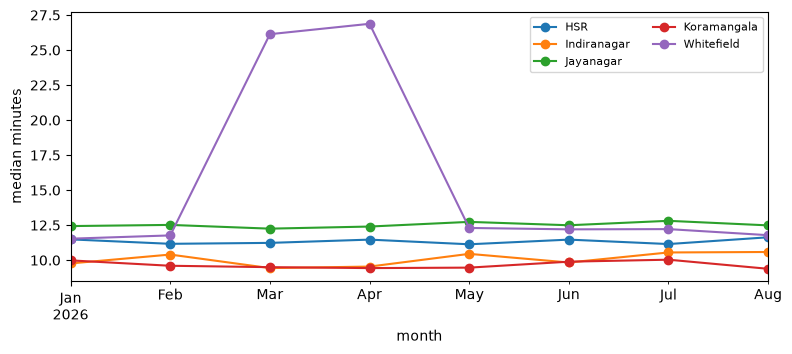

clinic,HSR,Indiranagar,Jayanagar,Koramangala,Whitefield
month,,,,,
2026-01-01,11.5,9.8,12.4,10.0,11.5
2026-02-01,11.2,10.4,12.5,9.6,11.8
2026-03-01,11.2,9.4,12.2,9.5,26.1
2026-04-01,11.5,9.5,12.4,9.4,26.9
2026-05-01,11.1,10.4,12.7,9.5,12.3
2026-06-01,11.5,9.8,12.5,9.9,12.2
2026-07-01,11.2,10.6,12.8,10.0,12.2
2026-08-01,11.6,10.6,12.5,9.4,11.8


In [12]:
# Given: monthly median consult minutes for each clinic (needs `minutes` from Check 6)
table = monthly_median(raw.assign(minutes=minutes), "minutes", by="clinic")
plt.show()
table.round(1)

In [13]:
# TODO(you): the timestamps should follow   check_in  <=  consult_start  <  consult_end
# 1. How many rows break each part of that order? How many have consult_start EXACTLY equal to check_in?
violations = pd.Series({
    "consult_start < check_in":        (raw["consult_start"] < raw["check_in"]).sum(),
    "consult_end <= consult_start":    (raw["consult_end"] <= raw["consult_start"]).sum(),
    "consult_start == check_in":       (raw["consult_start"] == raw["check_in"]).sum(),
    "consult_end == consult_start":    (raw["consult_end"] == raw["consult_start"]).sum(),
})
display(violations)

# 2. Where and when do those rows happen?     hint: groupby clinic and month

flags = raw.assign(
    month=raw["date"].dt.to_period("M"),
    start_before_checkin=raw["consult_start"] < raw["check_in"],
    end_not_after_start=raw["consult_end"] <= raw["consult_start"],
    start_eq_checkin=raw["consult_start"] == raw["check_in"],
)

cols = ["start_before_checkin", "end_not_after_start", "start_eq_checkin"]
display(flags.groupby("clinic")[cols].sum())
display(flags.groupby("month")[cols].sum())
display(flags.groupby(["clinic", "month"])[cols].sum().unstack("clinic"))

consult_start < check_in           0
consult_end <= consult_start       0
consult_start == check_in       1712
consult_end == consult_start       0
dtype: int64

,start_before_checkin,end_not_after_start,start_eq_checkin
clinic,,,
HSR,0,0,0
Indiranagar,0,0,0
Jayanagar,0,0,0
Koramangala,0,0,0
Whitefield,0,0,1712


,start_before_checkin,end_not_after_start,start_eq_checkin
month,,,
2026-01,0,0,0
2026-02,0,0,0
2026-03,0,0,921
2026-04,0,0,791
2026-05,0,0,0
2026-06,0,0,0
2026-07,0,0,0
2026-08,0,0,0


start_before_checkin                                               \
clinic                   HSR Indiranagar Jayanagar Koramangala Whitefield   
month                                                                       
2026-01                    0           0         0           0          0   
2026-02                    0           0         0           0          0   
2026-03                    0           0         0           0          0   
2026-04                    0           0         0           0          0   
2026-05                    0           0         0           0          0   
2026-06                    0           0         0           0          0   
2026-07                    0           0         0           0          0   
2026-08                    0           0         0           0          0   

        end_not_after_start                                               \
clinic                  HSR Indiranagar Jayanagar Koramangala Whitefield   
month                                                                      
2026-01                   0           0         0           0          0   
2026-02                   0           0         0           0          0   
2026-03                   0           0         0           0          0   
2026-04                   0           0         0           0          0   
2026-05                   0           0         0           0          0   
2026-06                   0           0         0           0          0   
2026-07                   0           0         0           0          0   
2026-08                   0           0         0           0          0   

        start_eq_checkin                                               
clinic               HSR Indiranagar Jayanagar Koramangala Whitefield  
month                                                                  
2026-01                0           0         0           0          0  
2026-02                0           0         0           0          0  
2026-03                0           0         0           0        921  
2026-04                0           0         0           0        791  
2026-05                0           0         0           0          0  
2026-06                0           0         0           0          0  
2026-07                0           0         0           0          0  
2026-08                0           0         0           0          0

## Check 8 - Leakage smells

**Why:** a feature is only allowed if it is **known when the slot is booked**, days before the visit. Fill in the table: for each column, is it known at booking? Is it the target or used to build it? Is it useless or risky?

| Column | Known at booking? | Use as a feature? | Why |
|---|---|---|---|
| appointment_id |yes |no |unique->identify the appointment but dont give info about the visit it self |
| date, slot_time |yes |yes |help with predict on taht day for time |
| clinic, doctor, department |yes | yes| need slot per deprt/doctor/clilic |
| patient_id, patient_name |yes |no |can be different while prediction for new appointment type this may not be known |
| age, prior_reports |yes |yes |this will be the signal for training the hidden rules the model need to precit |
| visit_type, teleconsult | yes| yes|need for solt |
| check_in |no |no |only known once patient arrived |
| consult_start, consult_end |no | no|only known once appointment stared |

Hint for `appointment_id`: are the ids random, or do they encode something else?

## Wrap-up

1. **How many of the 8 problem kinds did you log?** All 8 (duplicates, inconsistent labels, age 999, missing age, missing `consult_end`, impossible durations, Whitefield process change, broken timestamp order).

2. **MCAR / MAR / MNAR, and does dropping bias the data?**

| # | Problem | Type | Drop rows? |
|---|---|---|---|
| 1 | Duplicates | Not a missingness problem (copies) | Safe: drop the extra copy, keep one |
| 2 | Inconsistent labels | Not missing | Don't drop, normalise/map instead |
| 3 | Age 999 | Hidden missing, MCAR-like (spread evenly) | Better to set NaN and impute than drop |
| 4 | Missing age | MCAR-like (flat 1.6-2.1% across clinics) | Dropping is low risk, but imputing keeps rows |
| 5 | Missing `consult_end` | MCAR-like (flat across clinics and months); watch for MNAR if the very long visits are the ones left unclosed | Low risk to drop (0.27%), but check the missing rows are not mostly long visits |
| 6 | Impossible durations | Errors; possibly partly MNAR-like (the "forgot to close" long visits) | Drop the impossible ones, but only after confirming it does not remove a whole kind of visit |
| 7 | Whitefield Mar-Apr (`start == check_in`) | **MAR**: depends on clinic and period, which we can see | **Yes, biased**: dropping removes about 21% of Whitefield's rows (1,712 of 8,136) and two whole months |
| 8 | Order broken (0 rows in this export) | Random errors | Safe to drop (tiny) |

   **Whitefield, better fix than dropping:** `consult_start` is broken but `consult_end` is fine, and the other features (doctor, department, visit type, age, slot) are fine too. So keep the rows and treat only the *target/start* as bad: set `consult_start` to missing for those 1,712 rows and either (a) exclude them from computing the target while still using them for other analysis, or (b) re-estimate the true start (e.g. `consult_end` minus the typical duration for that doctor/visit type, from Whitefield's good months), or (c) add a "Whitefield Mar-Apr" flag so the model can separate the two processes. Note that for these rows `consult_end - check_in` is **wait + consult**, not consult time, so it must not be used as the target directly.

3. **Which problem hurts the model most if missed?** **The Whitefield change (#7).** It silently doubles the target (median ~26 vs ~12 min) for one clinic over two months, so the model would learn a false "Whitefield is slow" pattern. The other problems are small (<2% each) or easy to spot, while this one is large, systematic and looks like valid data.